### A/B TESTING ANALYSIS

**Goal:**  
Evaluate whether moving the first game gate from level 30 to level 40 has a statistically significant impact on user retention and engagement.

We compare key metrics between control (gate_30) and test (gate_40) groups and apply statistical tests to validate observed differences.

### 1. Metrics Definition

We evaluate the experiment using the following metrics:

- **Retention_1** – short-term retention (Day 1)
- **Retention_7** – long-term retention (Day 7) → *primary metric*
- **Sum_gamerounds** – user engagement over 14 days

Retention metrics are binary (0/1), while gamerounds is a continuous variable.

In [1]:
# Set working directory
import local_config
from local_config import directory_path
import os
os.chdir(directory_path)

# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv('data/cookie_cats.csv')

### 2. Metric Comparison (Descriptive Analysis)

We first compare average metric values between groups to understand the direction and magnitude of differences.

In [2]:
summary = df.groupby('version').agg(
    users=('userid', 'count'),
    total_gamerounds=('sum_gamerounds', 'sum'),
    avg_gamerounds=('sum_gamerounds', 'mean'),
    retention_1=('retention_1', 'mean'),
    retention_7=('retention_7', 'mean')
)

summary

,users,total_gamerounds,avg_gamerounds,retention_1,retention_7
version,,,,,
gate_30,44700,2344795,52.456264,0.448188,0.190201
gate_40,45489,2333530,51.298776,0.442283,0.182000


Initial observations:

- Retention differences between groups appear small
- Engagement (gamerounds) is lower in gate_40 group
- These differences require statistical validation

### 3. Metric Change

We evaluate the impact of the experiment using:
- Retention_1
- Retention_7 (primary metric)
- Average gamerounds

In [3]:
metrics = ['retention_1', 'retention_7', 'avg_gamerounds']
summary_metrics = summary[metrics]

In [4]:
table = summary_metrics.T
table['abs_change'] = (table['gate_40'] - table['gate_30']).round(4)
table['rel_change_%'] = (table['abs_change'] / table['gate_30'] * 100).round(2)
table = table.round(4)
table

version,gate_30,gate_40,abs_change,rel_change_%
retention_1,0.4482,0.4423,-0.0059,-1.32
retention_7,0.1902,0.1820,-0.0082,-4.31
avg_gamerounds,52.4563,51.2988,-1.1575,-2.21


Key observations:

- Retention_1 shows a slight decrease in the test group  
- Retention_7 also decreases in the test group, suggesting a potential negative trend in long-term retention
- Average gamerounds is lower in gate_40 group, indicating reduced engagement  

However, these differences need to be validated using statistical testing.

### 4. Statistical Testing

#### 4.1 Retention Metrics (Z-test for proportions)

Retention is a binary metric (0/1), where:
- 1 indicates the user returned
- 0 indicates the user did not return

We compare retention rates between the control group (gate_30) and test group (gate_40) using a z-test for proportions.

In [5]:
from statsmodels.stats.proportion import proportions_ztest

We calculate:
- number of users in each group
- number of retained users (successes)

These values are used as inputs for the z-test.

In [6]:
df_test = df.groupby('version').agg(
    total_users=('userid', 'count'),
    retained_users_d1=('retention_1', 'sum'),
    retained_users_d7=('retention_7', 'sum')
)

df_test

,total_users,retained_users_d1,retained_users_d7
version,,,
gate_30,44700,20034,8502
gate_40,45489,20119,8279


In [7]:
retention_rates = df_test.copy()
retention_rates['retention_d1_rate'] = retention_rates['retained_users_d1'] / retention_rates['total_users']
retention_rates['retention_d7_rate'] = retention_rates['retained_users_d7'] / retention_rates['total_users']

retention_rates

,total_users,retained_users_d1,retained_users_d7,retention_d1_rate,retention_d7_rate
version,,,,,
gate_30,44700,20034,8502,0.448188,0.190201
gate_40,45489,20119,8279,0.442283,0.182000


In [8]:
retention_d1_gate30 = retention_rates.loc['gate_30','retention_d1_rate'].round(4)
retention_d1_gate40 = retention_rates.loc['gate_40','retention_d1_rate'].round(4)
retention_d7_gate30 = retention_rates.loc['gate_30','retention_d7_rate'].round(4)
retention_d7_gate40 = retention_rates.loc['gate_40','retention_d7_rate'].round(4)

Retention rates:
- gate_30: 44.82% (Day 1), 19.02% (Day 7)
- gate_40: 44.23% (Day 1), 18.20% (Day 7)

**Hypotheses:**

- H0: retention rates are equal between groups  
- H1: retention rates are different between groups  

Significance level: α = 0.05

In [9]:
stat_d1, pval_d1 = proportions_ztest(
    [df_test.loc['gate_30','retained_users_d1'], df_test.loc['gate_40','retained_users_d1']],
    [df_test.loc['gate_30','total_users'], df_test.loc['gate_40','total_users']]
)

stat_d7, pval_d7 = proportions_ztest(
    [df_test.loc['gate_30','retained_users_d7'], df_test.loc['gate_40','retained_users_d7']],
    [df_test.loc['gate_30','total_users'], df_test.loc['gate_40','total_users']]
)

In [10]:
results_retention = pd.DataFrame({
    'metric': ['retention_1', 'retention_7'],
    'gate_30': [retention_d1_gate30, retention_d7_gate30],
    'gate_40': [retention_d1_gate40, retention_d7_gate40],
    'abs_change': [
        retention_d1_gate40 - retention_d1_gate30,
        retention_d7_gate40 - retention_d7_gate30
    ],
    'p_value': [pval_d1, pval_d7]
})

results_retention['significant'] = results_retention['p_value'] < 0.05

results_retention.round(4)

,metric,gate_30,gate_40,abs_change,p_value,significant
0,retention_1,0.4482,0.4423,-0.0059,0.0744,False
1,retention_7,0.1902,0.1820,-0.0082,0.0016,True


**Results:**

- Day 1 retention shows no statistically significant difference between groups  
- Day 7 retention is significantly lower in the gate_40 group  

**Interpretation:**

The experiment does not impact short-term retention, but has a statistically significant negative effect on long-term retention.

#### 4.2 Engagement Metric (Gamerounds)

Gamerounds is a continuous metric representing user engagement.

The distribution is right-skewed, therefore multiple methods are used to ensure robust comparison.

We apply:

- t-test → compares mean values  
- Mann-Whitney U test → compares distributions  
- Bootstrapping → estimates confidence interval of the mean difference  

---

### T-test

In [11]:
gate_30 = df[df['version'] == 'gate_30']['sum_gamerounds']
gate_40 = df[df['version'] == 'gate_40']['sum_gamerounds']

In [12]:
avg_gamerounds_gate30 = gate_30.mean().round(2)
avg_gamerounds_gate40 = gate_40.mean().round(2)

The average number of gamerounds:
- gate_30: 52.46 
- gate_40: 51.3

**Hypotheses:**

- H0: average numbers of gamerounds are equal between groups  
- H1: average numbers of gamerounds are different between groups  

Significance level: α = 0.05

In [13]:
from scipy.stats import ttest_ind

stat, pval = ttest_ind(gate_30, gate_40, equal_var=False)

effect_size = avg_gamerounds_gate40 - avg_gamerounds_gate30

In [14]:
results = {
    'metric': 'avg_gamerounds',
    'gate_30_mean': avg_gamerounds_gate30,
    'gate_40_mean': avg_gamerounds_gate40,
    'effect_size': round(effect_size, 2),
    't_statistic': round(stat, 4),
    'p_value': round(pval, 4)
}

pd.DataFrame([results])

,metric,gate_30_mean,gate_40_mean,effect_size,t_statistic,p_value
0,avg_gamerounds,52.46,51.3,-1.16,0.8854,0.3759


In [15]:
alpha = 0.05

if pval < alpha:
    print('Reject H0')
else:
    print('Fail to reject H0')

Fail to reject H0


**Results:**

- Average gamerounds (gate_30): 52.46  
- Average gamerounds (gate_40): 51.30  
- Difference: -1.16 rounds  

- t-statistic: 0.8854 
- p-value: 0.3759

**Conclusion:**

The difference in average gamerounds is not statistically significant at α = 0.05, suggesting no evidence of an impact on user engagement.

Although we use t-test to compare means, the skewed distribution of gamerounds may influence results. Therefore, we complement this analysis with non-parametric methods.

---

### Mann–Whitney U Test

To complement the t-test, we apply the Mann–Whitney U test, a non-parametric method that compares the distribution of values between groups.

Unlike the t-test, it does not rely on mean values and is more robust to skewed distributions and outliers.

The test ranks all observations and evaluates whether one group tends to have higher values than the other.

**Hypotheses:**

- H0: The distributions of gamerounds are equal between groups  
- H1: The distributions differ between groups  

Significance level: α = 0.05

In [16]:
from scipy.stats import mannwhitneyu

stat_mw, pval_mw = mannwhitneyu(gate_30, gate_40, alternative='two-sided')

In [17]:
results_mw = {
    'metric': 'sum_gamerounds',
    'test': 'Mann-Whitney U',
    'statistic': round(stat_mw, 2),
    'p_value': round(pval_mw, 4)
}

pd.DataFrame([results_mw])

,metric,test,statistic,p_value
0,sum_gamerounds,Mann-Whitney U,1.024331e+09,0.0502


**Results:**

- U-statistic: 1024331250.5  
- p-value: 0.0502  

**Conclusion:**

The difference in gamerounds distribution is not significant.

This suggests that users in one group do not consistently achieve higher engagement compared to the other.

Together with the t-test results, this indicates that there is no strong evidence of a difference in user engagement between groups.

Both mean-based and distribution-based comparisons lead to consistent conclusions. This strengthens confidence in the robustness of the results.

---

### Bootstrapping

To further validate the results, we apply bootstrapping to estimate the distribution of the difference in average gamerounds.

This approach does not rely on distributional assumptions and is robust to skewness and outliers.

In [19]:
n_iterations = 1000
bootstrap_diffs = []

for _ in range(n_iterations):
    sample_30 = gate_30.sample(frac=1, replace=True)
    sample_40 = gate_40.sample(frac=1, replace=True)
    
    diff = sample_40.mean() - sample_30.mean()
    bootstrap_diffs.append(diff)

In [20]:
bootstrap_df = pd.DataFrame({
    'diff': bootstrap_diffs
})

bootstrap_df.to_csv('Tableau/data/bootstrap_distribution.csv', index=False)

In [21]:
ci_lower = np.percentile(bootstrap_diffs, 2.5)
ci_upper = np.percentile(bootstrap_diffs, 97.5)

ci_lower, ci_upper

(np.float64(-4.20560760367467), np.float64(1.0254277499936906))

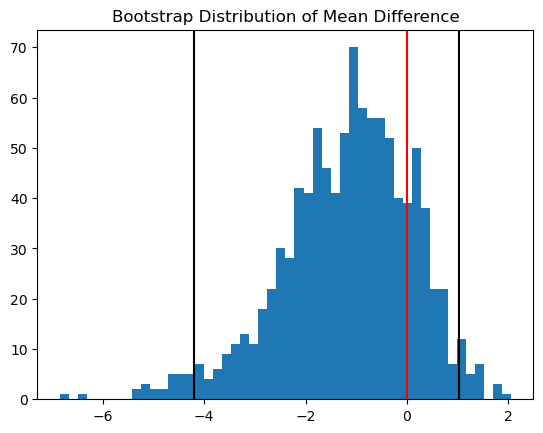

In [22]:
plt.hist(bootstrap_diffs, bins=50)
plt.axvline(ci_lower, color = 'black')
plt.axvline(ci_upper, color = 'black')
plt.axvline(0, color = 'red')
plt.title("Bootstrap Distribution of Mean Difference")
plt.show()

The 95% confidence interval for the difference in average gamerounds is:

[-3.86, 1.02]

Since the interval includes zero, the difference is not statistically significant.

These results are consistent with both the t-test and Mann-Whitney U test, reinforcing the conclusion that there is no strong evidence of a difference in user engagement between groups.

---

### 2.5 Results Summary

In [23]:
# -----------------------------
# 1. Changes (absolute)
# -----------------------------
change_d1 = retention_d1_gate40 - retention_d1_gate30
change_d7 = retention_d7_gate40 - retention_d7_gate30
change_gr = avg_gamerounds_gate40 - avg_gamerounds_gate30


# -----------------------------
# 2. Final results table
# -----------------------------
final_results = pd.DataFrame({
    'metric': ['retention_1', 'retention_7', 'avg_gamerounds'],

    # baseline (control group)
    'gate_30': [
        retention_d1_gate30,
        retention_d7_gate30,
        avg_gamerounds_gate30
    ],

    # test group
    'gate_40': [
        retention_d1_gate40,
        retention_d7_gate40,
        avg_gamerounds_gate40
    ],

    # absolute change
    'change': [
        change_d1,
        change_d7,
        change_gr
    ],

    # p-values
    'p_value': [pval_d1, pval_d7, pval],
})


# -----------------------------
# 3. Significance flag
# -----------------------------
final_results['significant'] = final_results['p_value'] < 0.05


# -----------------------------
# 4. Relative change (%)
# -----------------------------
final_results['rel_change_%'] = [
    (change_d1 / retention_d1_gate30) * 100,
    (change_d7 / retention_d7_gate30) * 100,
    (change_gr / avg_gamerounds_gate30) * 100
]


# -----------------------------
# 5. Formatting
# -----------------------------
final_results = final_results.round(4)

final_results

,metric,gate_30,gate_40,change,p_value,significant,rel_change_%
0,retention_1,0.4482,0.4423,-0.0059,0.0744,False,-1.3164
1,retention_7,0.1902,0.1820,-0.0082,0.0016,True,-4.3113
2,avg_gamerounds,52.4600,51.3000,-1.1600,0.3759,False,-2.2112


In [24]:
final_results.to_csv('Tableau/data/final_results.csv', index=False)

In [25]:
plot_data = final_results.melt(
    id_vars='metric',
    value_vars=['gate_30', 'gate_40'],
    var_name='group',
    value_name='value'
)

plot_data.to_csv('Tableau/data/plot_data.csv', index=False)

In [ ]:
#delta_data = final_results[['metric', 'change', 'rel_change_%']]
#delta_data.to_csv('Tableau/data/delta_data.csv', index=False)

### Final Results Summary

- No statistically significant difference in Day 1 retention  
- Statistically significant decrease in Day 7 retention in the test group  
- No statistically significant difference in average gamerounds  

### Business Interpretation

The experiment does not impact short-term retention or overall engagement, but has a negative effect on long-term retention.

This suggests that delaying the first gate may reduce long-term user retention.

### Recommendation

Based on the results, it is not recommended to move the gate from level 30 to level 40, as it negatively impacts long-term retention without improving engagement.

Final business interpretation is provided in the project README.